# Mini-Project 2 — Solar Micro-Grid Dispatch Planner

**Scenario.** A rural health centre in Kasese runs a micro-grid. Each day the energy drawn from solar panels ($x$) and batteries ($y$), in kWh, must satisfy

$$3x + 2y = D_1 \quad\text{(daytime load)}, \qquad 4x + y = D_2 \quad\text{(critical-equipment load)}.$$

**Data provenance.** The 30-day demand file is **illustrative (synthetic)**, generated with a fixed seed by `generate_demand_csv` (weekday/weekend pattern plus noise; parameters stated in Section 2b). The prices (solar UGX 150/kWh, battery UGX 450/kWh) are the assignment's illustrative values. The coefficients on $z$ and the third equation in the extension are our own stated assumptions.

All reusable logic lives in `src/microgrid.py` (tested in `tests/test_microgrid.py`).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import statistics
import timeit
import numpy as np
import matplotlib.pyplot as plt
from scipy import linalg

from src.microgrid import (
    MicroGrid, HybridMicroGrid, dispatch_plan, flag_infeasible, solve_nonnegative,
    read_demand, generate_demand_csv, load_demand_csv, daily_cost, WEEKDAYS,
)

SEED = 2026
DEMAND_CSV = PROJECT_ROOT / "data" / "microgrid_demand.csv"
PRICES = (150.0, 450.0)   # UGX per kWh: solar, battery (illustrative, from the assignment)
np.set_printoptions(precision=3, suppress=True)

## 1. The `MicroGrid` class and well-posedness (Task 1)

In matrix form the system is $A\mathbf{u} = \mathbf{d}$ with $A = \begin{pmatrix}3 & 2\\ 4 & 1\end{pmatrix}$, $\mathbf{u} = (x, y)$ and $\mathbf{d} = (D_1, D_2)$.

* **Determinant.** $\det A = 3\cdot1 - 2\cdot4 = -5 \neq 0$, so $A$ is invertible and **every day has exactly one solution**. A zero determinant would mean the two equations are parallel (no solution or infinitely many). The *sign* only says that the columns' orientation is flipped; its *size* is not a reliable measure of how safe the system is, because scaling an equation changes the determinant without changing the problem.
* **Condition number.** $\kappa(A) = \sigma_{\max}/\sigma_{\min}$, the ratio of the largest to smallest singular value. It bounds how much a *relative* error in the demands can be amplified in the solution: $\frac{\|\Delta\mathbf{u}\|}{\|\mathbf{u}\|} \le \kappa(A)\,\frac{\|\Delta\mathbf{d}\|}{\|\mathbf{d}\|}$. Here $\kappa = 3 + 2\sqrt{2} \approx 5.83$: well-conditioned (no numerical danger — problems start at roughly $10^{8}$ or more in double precision), but a 1 % metering error in the demands could move the allocation by up to about 6 %.

In [2]:
grid = MicroGrid()
print(grid)
print("Determinant (floating point):", grid.determinant, "  exact value: -5 (round-off in the last digit)")
print("Singular values:", np.linalg.svd(grid.A, compute_uv=False))
print("Condition number:", round(grid.condition_number, 6), "  exact 3 + 2*sqrt(2) =", round(3 + 2 * np.sqrt(2), 6))
print("Inverse matrix A^-1:\n", np.linalg.inv(grid.A))

MicroGrid(sources=('solar', 'battery'), det=-5, cond=5.828)
Determinant (floating point): -4.999999999999999   exact value: -5 (round-off in the last digit)
Singular values: [5.398 0.926]
Condition number: 5.828427   exact 3 + 2*sqrt(2) = 5.828427
Inverse matrix A^-1:
 [[-0.2  0.4]
 [ 0.8 -0.6]]


**Closed form (second method).** From $A^{-1} = \frac{1}{-5}\begin{pmatrix}1 & -2\\ -4 & 3\end{pmatrix}$:

$$x = \frac{2D_2 - D_1}{5}, \qquad y = \frac{4D_1 - 3D_2}{5}.$$

So $x \ge 0 \iff D_2 \ge D_1/2$ and $y \ge 0 \iff D_2 \le 4D_1/3$: **a day is physically feasible only when $0.5 \le D_2/D_1 \le 1.333$.**

In [3]:
d1, d2 = 80.0, 70.0
x, y = grid.solve_day(d1, d2)
print(f"solve_day({d1}, {d2})  -> x = {x:.4f} kWh solar, y = {y:.4f} kWh battery")
print(f"closed form          -> x = {(2*d2 - d1)/5:.4f}, y = {(4*d1 - 3*d2)/5:.4f}")
print("check A @ u =", grid.A @ np.array([x, y]))

solve_day(80.0, 70.0)  -> x = 12.0000 kWh solar, y = 22.0000 kWh battery
closed form          -> x = 12.0000, y = 22.0000
check A @ u = [80. 70.]


## 2. Input modes (Task 2)

### 2a. Interactive input with validation

`read_demand` repeats the prompt until `parse_demand` accepts the text: it rejects empty input, non-numbers, non-finite values and negatives, printing the reason each time. The input function is a parameter (`input_fn`), so the same code can be driven by a real keyboard or by a script. A live `input()` would block **Restart & Run All**, so the demonstration below feeds scripted answers; set `INTERACTIVE = True` to type values yourself.

In [4]:
scripted = iter(["", "eighty", "-12", "80", "70"])     # empty, non-numeric, negative, then valid
def fake_input(prompt):
    answer = next(scripted)
    print(f"{prompt}{answer!r}")
    return answer

d1 = read_demand("D1 (daytime load, kWh): ", input_fn=fake_input)
d2 = read_demand("D2 (critical load, kWh): ", input_fn=fake_input)
print(f"\nAccepted D1 = {d1}, D2 = {d2} -> allocation {grid.solve_day(d1, d2)} kWh")

D1 (daytime load, kWh): ''
  Invalid input - Empty input: please type a number of kWh. Try again.
D1 (daytime load, kWh): 'eighty'
  Invalid input - 'eighty' is not a number. Try again.
D1 (daytime load, kWh): '-12'
  Invalid input - Demand cannot be negative. Try again.
D1 (daytime load, kWh): '80'
D2 (critical load, kWh): '70'

Accepted D1 = 80.0, D2 = 70.0 -> allocation [12. 22.] kWh


In [5]:
INTERACTIVE = False   # set to True to type the demands yourself (keep False for Restart & Run All)
if INTERACTIVE:
    d1 = read_demand("D1 (daytime load, kWh): ")
    d2 = read_demand("D2 (critical load, kWh): ")
    print("Allocation (solar, battery) in kWh:", grid.solve_day(d1, d2))
else:
    print("Interactive mode is off.")

Interactive mode is off.


### 2b. 30 days of demand from a CSV file

`generate_demand_csv` writes **illustrative** data with these stated assumptions: day 1 is a Monday; $D_1$ averages 80 kWh on weekdays and 80 % of that at weekends (outpatient clinics mostly run on weekdays); $D_2$ averages 70 kWh and 95 % of that at weekends (fridges, oxygen and lighting barely change); each value gets independent multiplicative noise $1 + N(0, 0.06)$; values are rounded to 0.1 kWh. The file is then read back with `load_demand_csv`, which validates its columns and values.

In [6]:
generate_demand_csv(DEMAND_CSV, days=30, seed=SEED)
demands = load_demand_csv(DEMAND_CSV)
weekdays = np.array([WEEKDAYS[i % 7] for i in range(len(demands))])
weekend = np.isin(weekdays, ["Sat", "Sun"])

print(f"Loaded {demands.shape[0]} days from {DEMAND_CSV.name}")
print("First 7 days (D1, D2):\n", demands[:7])
print(f"Mean D1: weekdays {demands[~weekend, 0].mean():.1f}, weekends {demands[weekend, 0].mean():.1f} kWh")
print(f"Mean D2: weekdays {demands[~weekend, 1].mean():.1f}, weekends {demands[weekend, 1].mean():.1f} kWh")

Loaded 30 days from microgrid_demand.csv
First 7 days (D1, D2):
 [[76.2 71. ]
 [70.9 75.9]
 [83.1 68.8]
 [78.5 71.3]
 [78.7 69.1]
 [66.8 68.6]
 [63.8 66.2]]
Mean D1: weekdays 80.1, weekends 64.1 kWh
Mean D2: weekdays 71.6, weekends 68.9 kWh


## 3. Solving all 30 days: loop versus vectorised (Task 3)

The loop calls `scipy.linalg.solve` 30 times with a length-2 right-hand side. The vectorised version passes a single $2\times30$ right-hand side, so the matrix is factorised **once** and the 30 solutions are computed together in compiled code.

In [7]:
loop_solution = grid.solve_loop(demands)
vec_solution = grid.solve_vectorised(demands)
print("Identical results:", np.allclose(loop_solution, vec_solution))
print("Max absolute difference:", np.abs(loop_solution - vec_solution).max())
print("Closed-form check:", np.allclose(vec_solution[:, 0], (2 * demands[:, 1] - demands[:, 0]) / 5))

N = 200
loop_t = min(timeit.repeat(lambda: grid.solve_loop(demands), number=N, repeat=5)) / N
vec_t = min(timeit.repeat(lambda: grid.solve_vectorised(demands), number=N, repeat=5)) / N
print(f"\nLoop:       {loop_t * 1e6:8.1f} microseconds per 30-day solve")
print(f"Vectorised: {vec_t * 1e6:8.1f} microseconds per 30-day solve")
print(f"Speed-up:   {loop_t / vec_t:.0f}x  (exact numbers depend on the machine)")

Identical results: True
Max absolute difference: 3.552713678800501e-15
Closed-form check: True



Loop:         2142.9 microseconds per 30-day solve
Vectorised:    235.7 microseconds per 30-day solve
Speed-up:   9x  (exact numbers depend on the machine)


**Comment.** Both approaches give identical answers; the vectorised call is typically tens of times faster. The gain is not in the arithmetic — solving a $2\times2$ system is trivial — but in **overhead**: the loop pays Python-level costs (function call, input checks, matrix factorisation) 30 times, the vectorised version once. For 30 days either is instant, so the practical point is scaling: for a year of 15-minute intervals (≈35,000 solves) the difference becomes material. We report the best of 5 repeats to reduce noise from other programs running.

## 4. Physically infeasible days (Task 4)

A negative $x$ or $y$ would mean drawing negative energy, which is impossible. `flag_infeasible` marks days with any value below $-10^{-9}$ (the tolerance stops floating-point round-off such as $-10^{-15}$ being flagged).

**Handling strategy (chosen and justified).** On an infeasible day no non-negative allocation satisfies both equations exactly. We use **non-negative least squares** (`scipy.optimize.nnls`), which finds the allocation $\mathbf{u} \ge 0$ that comes closest to meeting both loads, and we **report the unmet demand** $\mathbf{d} - A\mathbf{u}$ per constraint. Clipping negatives to zero was rejected: it silently breaks both equations without telling the operator by how much. Feasible days keep their exact solution.

In [8]:
plan = dispatch_plan(grid, demands)
ratio = demands[:, 1] / demands[:, 0]
print("Infeasible days in the 30-day file:", np.flatnonzero(plan["infeasible"]) + 1)
print(f"D2/D1 ranges from {ratio.min():.3f} to {ratio.max():.3f}; feasible band is [0.500, 1.333]")
print("Smallest solar and battery values:", plan["exact"].min(axis=0), "kWh")

Infeasible days in the 30-day file: []
D2/D1 ranges from 0.736 to 1.173; feasible band is [0.500, 1.333]
Smallest solar and battery values: [8.54 5.9 ] kWh


**None of the 30 generated days is infeasible.** With the stated assumptions, $D_2/D_1$ stays well inside the feasible band, so noise never pushes a day over the boundary. We did not tune the seed to manufacture infeasible days. To show that the detection and handling work, here is a hand-made day where the critical load is high relative to the daytime load ($D_1 = 40$, $D_2 = 70$, ratio 1.75):

In [9]:
bad_day = np.array([40.0, 70.0])
exact = grid.solve_day(*bad_day)
allocation, unmet = solve_nonnegative(grid, bad_day)
print("Exact solution:     ", exact, "-> infeasible:", flag_infeasible(exact)[0])
print("NNLS allocation:    ", allocation, "kWh (solar, battery)")
print("Unmet demand:       ", unmet, "kWh (daytime, critical); positive = shortfall, negative = surplus")
print("Check A @ u + unmet:", grid.A @ allocation + unmet)

combined = dispatch_plan(grid, np.vstack([demands[:2], bad_day]))
print("\nPlan on [day 1, day 2, bad day]: infeasible =", combined["infeasible"])

Exact solution:      [ 20. -10.] -> infeasible: True
NNLS allocation:     [16.  0.] kWh (solar, battery)
Unmet demand:        [-8.  6.] kWh (daytime, critical); positive = shortfall, negative = surplus
Check A @ u + unmet: [40. 70.]

Plan on [day 1, day 2, bad day]: infeasible = [False False  True]


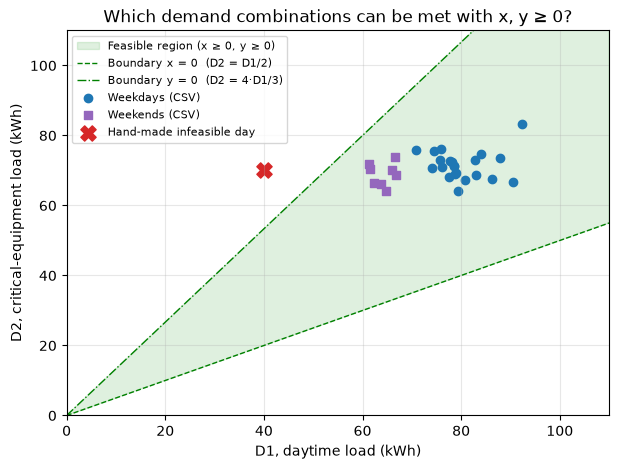

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
d1_line = np.linspace(0, 110, 50)
ax.fill_between(d1_line, d1_line / 2, 4 * d1_line / 3, color="tab:green", alpha=0.15, label="Feasible region (x ≥ 0, y ≥ 0)")
ax.plot(d1_line, d1_line / 2, "g--", linewidth=1, label="Boundary x = 0  (D2 = D1/2)")
ax.plot(d1_line, 4 * d1_line / 3, "g-.", linewidth=1, label="Boundary y = 0  (D2 = 4·D1/3)")
ax.scatter(demands[~weekend, 0], demands[~weekend, 1], color="tab:blue", label="Weekdays (CSV)")
ax.scatter(demands[weekend, 0], demands[weekend, 1], color="tab:purple", marker="s", label="Weekends (CSV)")
ax.scatter(*bad_day, color="tab:red", marker="X", s=120, label="Hand-made infeasible day")
ax.set_xlim(0, 110); ax.set_ylim(0, 110)
ax.set_xlabel("D1, daytime load (kWh)"); ax.set_ylabel("D2, critical-equipment load (kWh)")
ax.set_title("Which demand combinations can be met with x, y ≥ 0?")
ax.legend(fontsize=8, loc="upper left"); ax.grid(alpha=0.3)
plt.show()

The chart shows why no generated day failed: every point sits comfortably inside the feasible wedge. Weekend points (purple) sit higher in the wedge, closer to the $y = 0$ boundary, because $D_1$ drops more than $D_2$ at weekends — the battery share shrinks. A health centre whose critical load is high relative to its daytime load would leave the wedge and need either extra sources or load shedding.

## 5. Descriptive statistics of solar and battery use (Task 5)

In [11]:
alloc = plan["allocation"]
print(f"{'Source':<8} {'Mean':>7} {'Variance':>9} {'SD':>6} {'CV':>6} {'Min':>6} {'Max':>6}   (kWh)")
for i, name in enumerate(grid.source_names):
    v = alloc[:, i].tolist()
    m, var, sd = statistics.mean(v), statistics.variance(v), statistics.stdev(v)
    print(f"{name:<8} {m:7.2f} {var:9.2f} {sd:6.2f} {sd/m:6.3f} {min(v):6.1f} {max(v):6.1f}")

print(f"\nWeekday vs weekend means: solar {alloc[~weekend, 0].mean():.1f} vs {alloc[weekend, 0].mean():.1f} kWh, "
      f"battery {alloc[~weekend, 1].mean():.1f} vs {alloc[weekend, 1].mean():.1f} kWh")

Source      Mean  Variance     SD     CV    Min    Max   (kWh)
solar      13.19      4.03   2.01  0.152    8.5   16.5
battery    18.13     44.10   6.64  0.366    5.9   32.4

Weekday vs weekend means: solar 12.6 vs 14.7 kWh, battery 21.1 vs 9.9 kWh


**Which source is more volatile?** The **battery**, by every measure: its standard deviation is more than three times solar's, and since both are in kWh with different means we also compare the coefficient of variation (SD ÷ mean), which is roughly 0.37 for the battery against 0.15 for solar. The closed form explains why: $y = (4D_1 - 3D_2)/5$ puts a large weight on $D_1$, and $D_1$ is the load with the strong weekday/weekend swing. In this model the battery absorbs the weekly pattern — its mean falls from about 21 kWh on weekdays to about 10 kWh at weekends — while solar actually *rises* slightly at weekends ($x = (2D_2 - D_1)/5$ grows when $D_1$ falls). That counter-intuitive result is a property of the assignment's fixed coefficients, not of real solar output, which depends on sunshine rather than on demand.

## 6. Energy cost (Task 6)

Daily cost $= 150x + 450y$ UGX (illustrative prices), using the feasible plan. The monthly cost is the sum over the 30 days.

In [12]:
costs = daily_cost(alloc, PRICES)
print(f"Daily cost: mean UGX {costs.mean():,.0f}, min {costs.min():,.0f} (day {costs.argmin() + 1}, {weekdays[costs.argmin()]}), "
      f"max {costs.max():,.0f} (day {costs.argmax() + 1}, {weekdays[costs.argmax()]})")
print(f"Monthly (30-day) cost: UGX {costs.sum():,.0f}")
print(f"Battery share of monthly cost: {450 * alloc[:, 1].sum() / costs.sum():.0%}")
x1, y1 = alloc[0]
print(f"Hand check day 1: 150 x {x1:.2f} + 450 x {y1:.2f} = {150*x1 + 450*y1:,.2f}  vs  module {costs[0]:,.2f}")

Daily cost: mean UGX 10,138, min 5,130 (day 14, Sun), max 15,879 (day 24, Wed)
Monthly (30-day) cost: UGX 304,125
Battery share of monthly cost: 80%
Hand check day 1: 150 x 13.16 + 450 x 18.36 = 10,236.00  vs  module 10,236.00


## 7. Daily solar vs battery use with daily cost (Task 7)

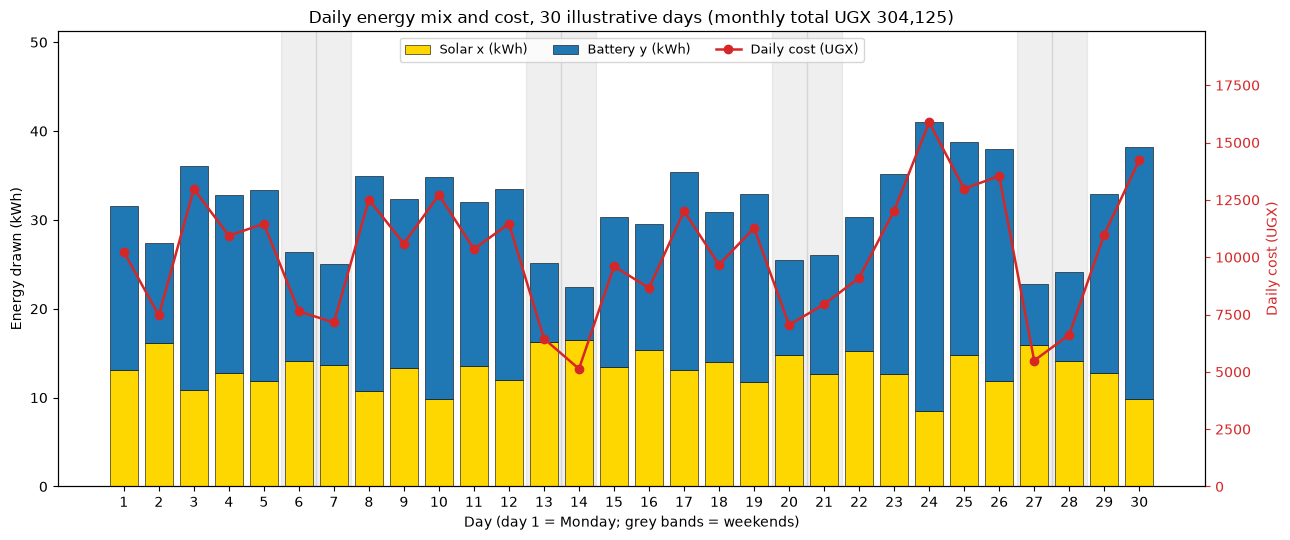

In [13]:
days = np.arange(1, len(alloc) + 1)
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.bar(days, alloc[:, 0], color="gold", edgecolor="black", linewidth=0.4, label="Solar x (kWh)")
ax.bar(days, alloc[:, 1], bottom=alloc[:, 0], color="tab:blue", edgecolor="black", linewidth=0.4, label="Battery y (kWh)")
for d in days[weekend]:
    ax.axvspan(d - 0.5, d + 0.5, color="grey", alpha=0.12, zorder=0)
ax.set_xlabel("Day (day 1 = Monday; grey bands = weekends)")
ax.set_ylabel("Energy drawn (kWh)")
ax.set_xticks(days)

ax2 = ax.twinx()
ax2.plot(days, costs, color="tab:red", marker="o", linewidth=1.8, label="Daily cost (UGX)")
ax2.set_ylabel("Daily cost (UGX)", color="tab:red")
ax2.tick_params(axis="y", colors="tab:red")
ax2.set_ylim(0, costs.max() * 1.25)

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.set_ylim(0, (alloc.sum(axis=1)).max() * 1.25)
ax.legend(h1 + h2, l1 + l2, loc="upper center", ncol=3, fontsize=9)
ax.set_title(f"Daily energy mix and cost, 30 illustrative days (monthly total UGX {costs.sum():,.0f})")
fig.tight_layout()
plt.show()

**Reading the chart.** The cost line tracks the battery (blue) segment far more closely than the solar (gold) segment: battery energy costs three times as much, so the most expensive days are weekdays with a large battery share and the cheapest are weekends, when the battery share collapses. Total energy drawn ($x + y = (3D_1 - D_2)/5$) also falls at weekends, but cost falls proportionally more, because the reduction comes almost entirely from the expensive battery while solar rises slightly. **Cost is driven mainly by the mix, not just the volume.**

## 8. Extension: `HybridMicroGrid` with a diesel generator

`HybridMicroGrid(MicroGrid)` inherits all validation and solving; it only changes the default matrix and source names. Our stated third constraint is the total metered energy:

$$3x + 2y + z = D_1,\qquad 4x + y + 2z = D_2,\qquad x + y + z = D_3.$$

In [14]:
hybrid = HybridMicroGrid()
print(hybrid)
example = (75.0, 70.0, 35.0)
print("solve_day", example, "->", hybrid.solve_day(*example), "kWh (solar, battery, diesel)")

day_100 = hybrid.solve_day(100, 90, 40)
print("solve_day (100, 90, 40) ->", day_100, "-> infeasible:", flag_infeasible(day_100)[0])

HybridMicroGrid(sources=('solar', 'battery', 'diesel'), det=-4, cond=10.06)
solve_day (75.0, 70.0, 35.0) -> [10. 20.  5.] kWh (solar, battery, diesel)
solve_day (100, 90, 40) -> [17.5 25.  -2.5] -> infeasible: True


The 3×3 system is still well-posed ($\det = -4$) but its condition number is higher (≈10 versus ≈5.8), so it is more sensitive to measurement error. The second example shows that adding a source does not guarantee feasibility: the demands (100, 90, 40) require **negative diesel**, so the same NNLS handling would be needed.

**What if the new equation is linearly dependent on the others?** Suppose the third constraint were "daytime load plus critical load", i.e. row 3 = row 1 + row 2: $7x + 3y + 3z = D_3$. Then $A$ has rank 2 and determinant 0:

In [15]:
dependent = np.array([[3, 2, 1], [4, 1, 2], [7, 3, 3]], dtype=float)
print("det =", np.linalg.det(dependent), " rank =", np.linalg.matrix_rank(dependent))

import warnings
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    try:
        garbage = linalg.solve(dependent, [75, 70, 150])
        print("scipy.linalg.solve did NOT raise; it returned", garbage)
    except linalg.LinAlgError as err:
        print("scipy.linalg.solve raised LinAlgError:", err)
for w in caught:
    print("  warning issued:", type(w.message).__name__, "-", str(w.message)[:80])

try:
    HybridMicroGrid(dependent)
except ValueError as err:
    print("HybridMicroGrid raised ValueError:", err)

print("\nNearly dependent: row 3 = row 1 + row 2 + (0, 0, eps)")
for eps in (1e-1, 1e-3, 1e-6):
    A = dependent.copy(); A[2, 2] += eps
    consistent = linalg.solve(A, [75, 70, 145])       # D3 = D1 + D2 exactly
    off_by_one = linalg.solve(A, [75, 70, 146])       # D3 off by 1 kWh
    print(f"  eps={eps:g}: cond = {np.linalg.cond(A):.3g}; D3=145 -> {np.round(consistent, 2)}; D3=146 -> {np.round(off_by_one, 1)}")

det = 2.2204460492503135e-15  rank = 2
scipy.linalg.solve did NOT raise; it returned [ 6.755e+15 -4.504e+15 -1.126e+16]
  warning issued: LinAlgWarning - An ill-conditioned matrix detected: slice 0 has rcond = 1.7080354225002412e-17.
HybridMicroGrid raised ValueError: The system is singular (rank 2 < 3): at least one equation is a linear combination of the others, so there is either no solution or infinitely many. Replace the dependent equation with independent information.

Nearly dependent: row 3 = row 1 + row 2 + (0, 0, eps)
  eps=0.1: cond = 215; D3=145 -> [13. 18. -0.]; D3=146 -> [ 7. 22. 10.]
  eps=0.001: cond = 2.14e+04; D3=145 -> [13. 18. -0.]; D3=146 -> [-587.  418. 1000.]
  eps=1e-06: cond = 2.14e+07; D3=145 -> [13. 18. -0.]; D3=146 -> [-599987.  400018. 1000000.]


**Interpretation.** A dependent third equation adds **no new information**: it is already implied by the first two. If $D_3$ happens to equal $D_1 + D_2$, there are infinitely many allocations; if it does not, there are none. **Check the output above.** Floating-point round-off leaves the determinant at about $10^{-15}$ instead of exactly 0, so `scipy` may *not* raise an error: in our development run (SciPy 1.17) it only issued an ill-conditioning warning and returned a meaningless answer of order $10^{16}$ kWh. Depending on the SciPy version and round-off it can instead raise `LinAlgError`; the code above handles both. A warning is easy to miss in a pipeline, which is exactly why `MicroGrid` checks the matrix rank up front and refuses with an explanation. The *nearly* dependent case is more dangerous because it does not raise an error: the condition number explodes, and a 1 kWh change in $D_3$ swings the diesel allocation by $1/\varepsilon$ kWh — a million kWh for $\varepsilon = 10^{-6}$ — and drives solar strongly negative. A useful third constraint must measure something genuinely independent, such as total metered energy.

## 9. Findings & Limitations

*Word count: approximately 270.*

**Findings.** The dispatch system is well-posed: its determinant is −5, so every day has exactly one solution, and its condition number of about 5.8 means measurement errors in the demands are amplified by at most about six times. Under our illustrative weekly pattern, all 30 days were physically feasible, because the ratio of critical to daytime load stayed between 0.74 and 1.17, inside the feasible band of 0.5–1.33. The battery is the volatile source (coefficient of variation ≈0.37 against ≈0.15 for solar) because the model makes it absorb the weekday–weekend swing in daytime load. Since battery energy costs three times as much as solar, the energy mix drives cost more than total volume does (the battery accounts for about 80 % of spending), which totals about UGX 304,000 for the month. Vectorised solving gives identical answers to the loop and is many times faster, which matters only at much larger scales.

**Limitations.** The demand data are synthetic, so the volatility and cost figures describe our assumptions, not the Kasese facility. The fixed coefficients imply that solar use *rises* when daytime demand falls, which is physically implausible: real solar output depends on sunshine, battery state of charge and capacity limits, none of which the model includes. The NNLS handling treats over-supply and under-supply as equally bad; for a health centre a shortfall on critical equipment matters far more, so a weighted or priority-based rule would be better. The diesel extension's coefficients and third constraint are our own assumptions, and without a diesel price its cost cannot be assessed. Timing results depend on the machine and are a relative comparison only.